# ARTI 404 – Image Processing 2240002411
## Lab 6: Filtering in the Frequency Domain

## Setup

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from numpy.fft import fft2, ifft2, fftshift, ifftshift
from skimage import data, io, img_as_ubyte
from skimage.transform import resize

os.makedirs('images', exist_ok=True)

# Save the original image used in this lab
io.imsave('images/cameraman_original.png', data.camera())

def save_gray(arr, fname):
    """Save a float array as an 8-bit PNG (min-max normalised for display)."""
    a = arr.astype(float)
    a = (a - a.min()) / (a.max() - a.min() + 1e-12)
    io.imsave(os.path.join('images', fname), img_as_ubyte(a))

# Part A

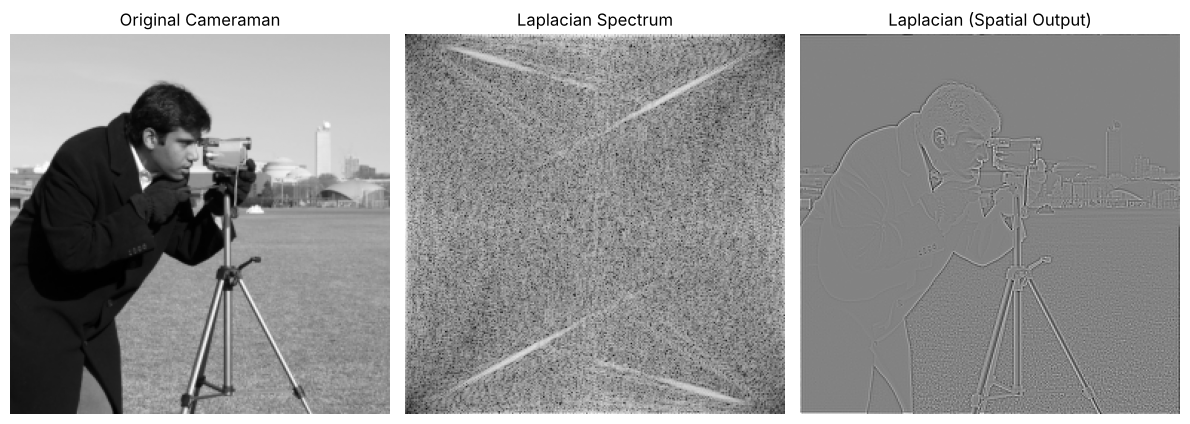

In [2]:
# Load cameraman image (already grayscale) and resize for faster FFT
image = data.camera()
image = resize(image, (256, 256))
M, N = image.shape

# Frequency grid (in fft order: DC at [0, 0])
u = np.fft.fftfreq(M).reshape(-1, 1)
v = np.fft.fftfreq(N).reshape(1, -1)

# Laplacian filter in the frequency domain
laplacian_filter = -4 * (np.pi ** 2) * (u**2 + v**2)

# Forward FFT, multiply, inverse FFT
F = np.fft.fft2(image)
F_lap = F * laplacian_filter
laplacian_image = np.fft.ifft2(F_lap).real

io.imsave('images/cameraman_256.png', img_as_ubyte(image))
save_gray(laplacian_image, 'laplacian_spatial_output.png')

plt.figure(figsize=(12, 5))
plt.subplot(1, 3, 1); plt.imshow(image, cmap='gray'); plt.title('Original Cameraman'); plt.axis('off')
plt.subplot(1, 3, 2); plt.imshow(np.log(1 + np.abs(F_lap)), cmap='gray'); plt.title('Laplacian Spectrum'); plt.axis('off')
plt.subplot(1, 3, 3); plt.imshow(laplacian_image, cmap='gray'); plt.title('Laplacian (Spatial Output)'); plt.axis('off')
plt.tight_layout(); plt.savefig('images/procedure_laplacian.png', dpi=100, bbox_inches='tight'); plt.show()

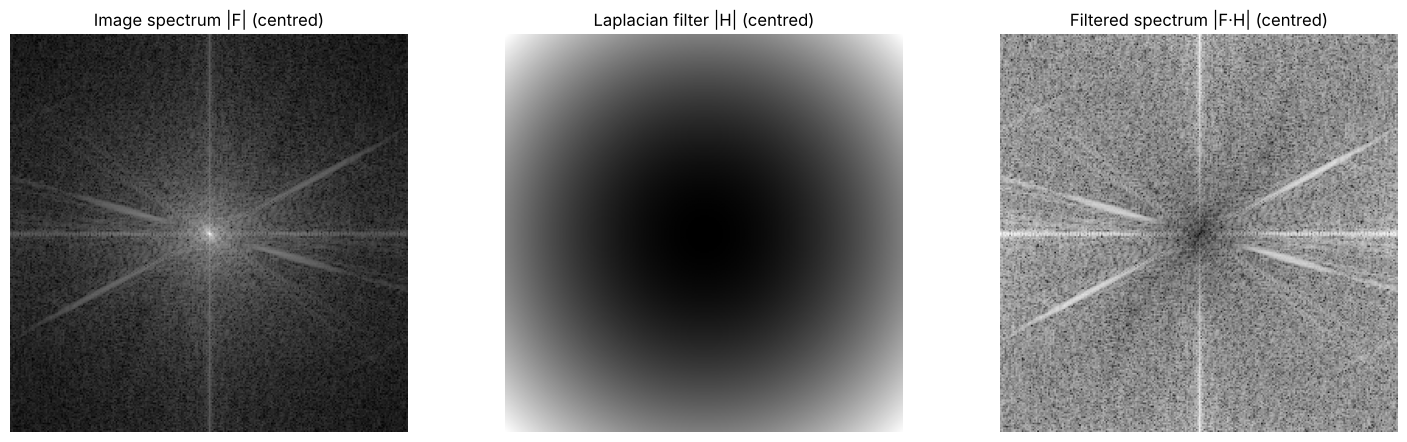

In [3]:
plt.figure(figsize=(15, 4.5))
plt.subplot(1, 3, 1); plt.imshow(np.log(1 + np.abs(fftshift(F))), cmap='gray'); plt.title('Image spectrum |F| (centred)'); plt.axis('off')
plt.subplot(1, 3, 2); plt.imshow(fftshift(np.abs(laplacian_filter)), cmap='gray'); plt.title('Laplacian filter |H| (centred)'); plt.axis('off')
plt.subplot(1, 3, 3); plt.imshow(np.log(1 + np.abs(fftshift(F_lap))), cmap='gray'); plt.title('Filtered spectrum |F·H| (centred)'); plt.axis('off')
plt.tight_layout(); plt.savefig('images/procedure_laplacian_spectra_centred.png', dpi=100, bbox_inches='tight'); plt.show()

# Part B

In [4]:
# 1. Load and resize image
image = resize(data.camera(), (256, 256))

# 2. Sobel filters
sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]])

sobel_y = np.array([[-1, -2, -1],
                    [ 0,  0,  0],
                    [ 1,  2,  1]])

# 3. Proper padding and centering of kernel in spatial domain
def center_embed_kernel(kernel, shape):
    padded = np.zeros(shape)
    kh, kw = kernel.shape
    ph, pw = shape
    # Find center coordinates
    cy, cx = ph // 2, pw // 2
    # Insert kernel centered at the image center
    padded[cy - kh//2:cy - kh//2 + kh, cx - kw//2:cx - kw//2 + kw] = kernel
    return fft2(ifftshift(padded))   # Shift before FFT to place (0,0) at top-left

# Compute FFT of image
F_img = fft2(image)

# FFT of centered Sobel filters (use the provided function)
H_x = center_embed_kernel(sobel_x, image.shape)
H_y = center_embed_kernel(sobel_y, image.shape)

# 4. Multiply in the frequency domain
F_gx = F_img * H_x
F_gy = F_img * H_y

# 5. Inverse FFT -> spatial edge maps
gx = np.real(ifft2(F_gx))
gy = np.real(ifft2(F_gy))
magnitude = np.sqrt(gx**2 + gy**2)

print('Image shape:', image.shape, '| filter FFT shape:', H_x.shape)
print('Max imaginary part left after ifft2 (should be ~0):', np.abs(np.imag(ifft2(F_gx))).max())

save_gray(gx, 'sobel_x_freq.png')
save_gray(gy, 'sobel_y_freq.png')
save_gray(magnitude, 'sobel_magnitude_freq.png')

Image shape: (256, 256) | filter FFT shape: (256, 256)
Max imaginary part left after ifft2 (should be ~0): 7.658579795395912e-16


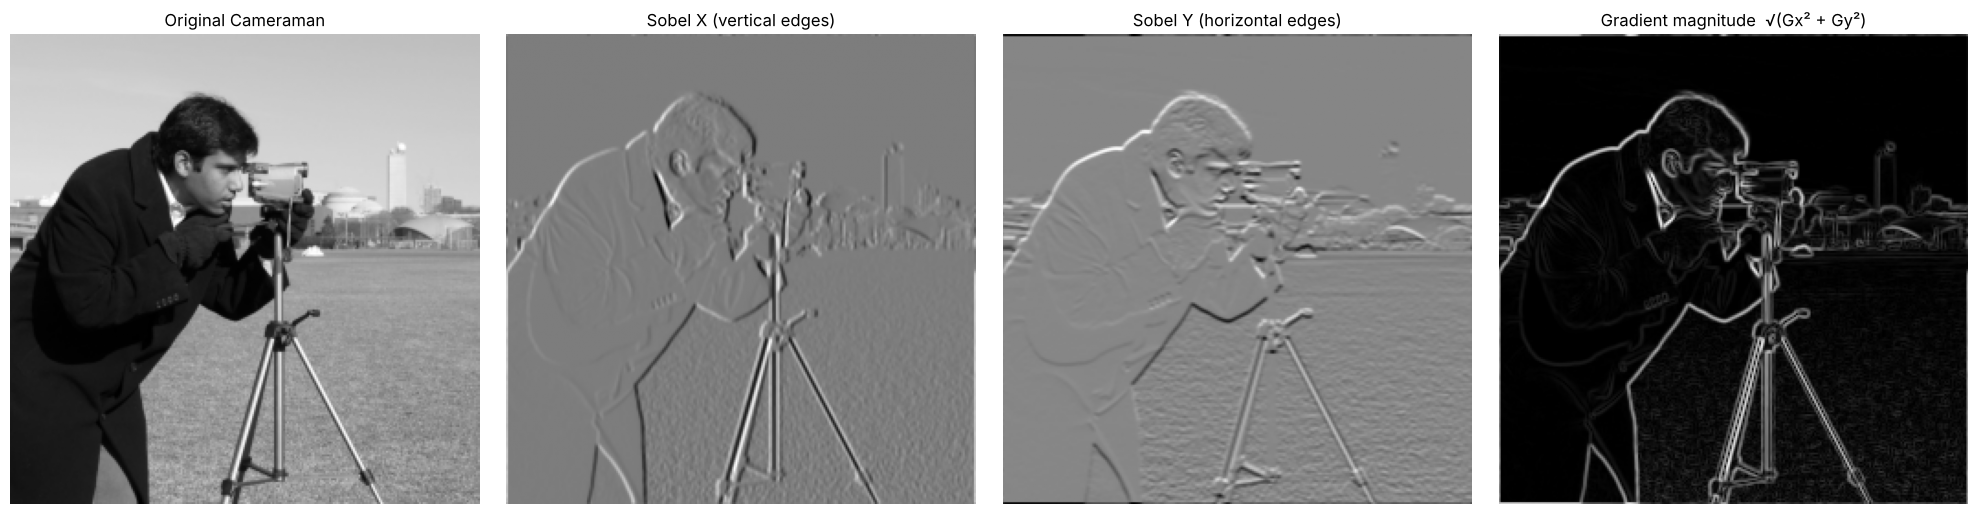

In [5]:
# Plot: original, Sobel-x, Sobel-y and gradient magnitude
fig, ax = plt.subplots(1, 4, figsize=(20, 5))
ax[0].imshow(image, cmap='gray');     ax[0].set_title('Original Cameraman')
ax[1].imshow(gx, cmap='gray');        ax[1].set_title('Sobel X (vertical edges)')
ax[2].imshow(gy, cmap='gray');        ax[2].set_title('Sobel Y (horizontal edges)')
ax[3].imshow(magnitude, cmap='gray'); ax[3].set_title('Gradient magnitude  √(Gx² + Gy²)')
for a in ax: a.axis('off')
plt.tight_layout(); plt.savefig('images/task1_sobel_frequency.png', dpi=100, bbox_inches='tight'); plt.show()

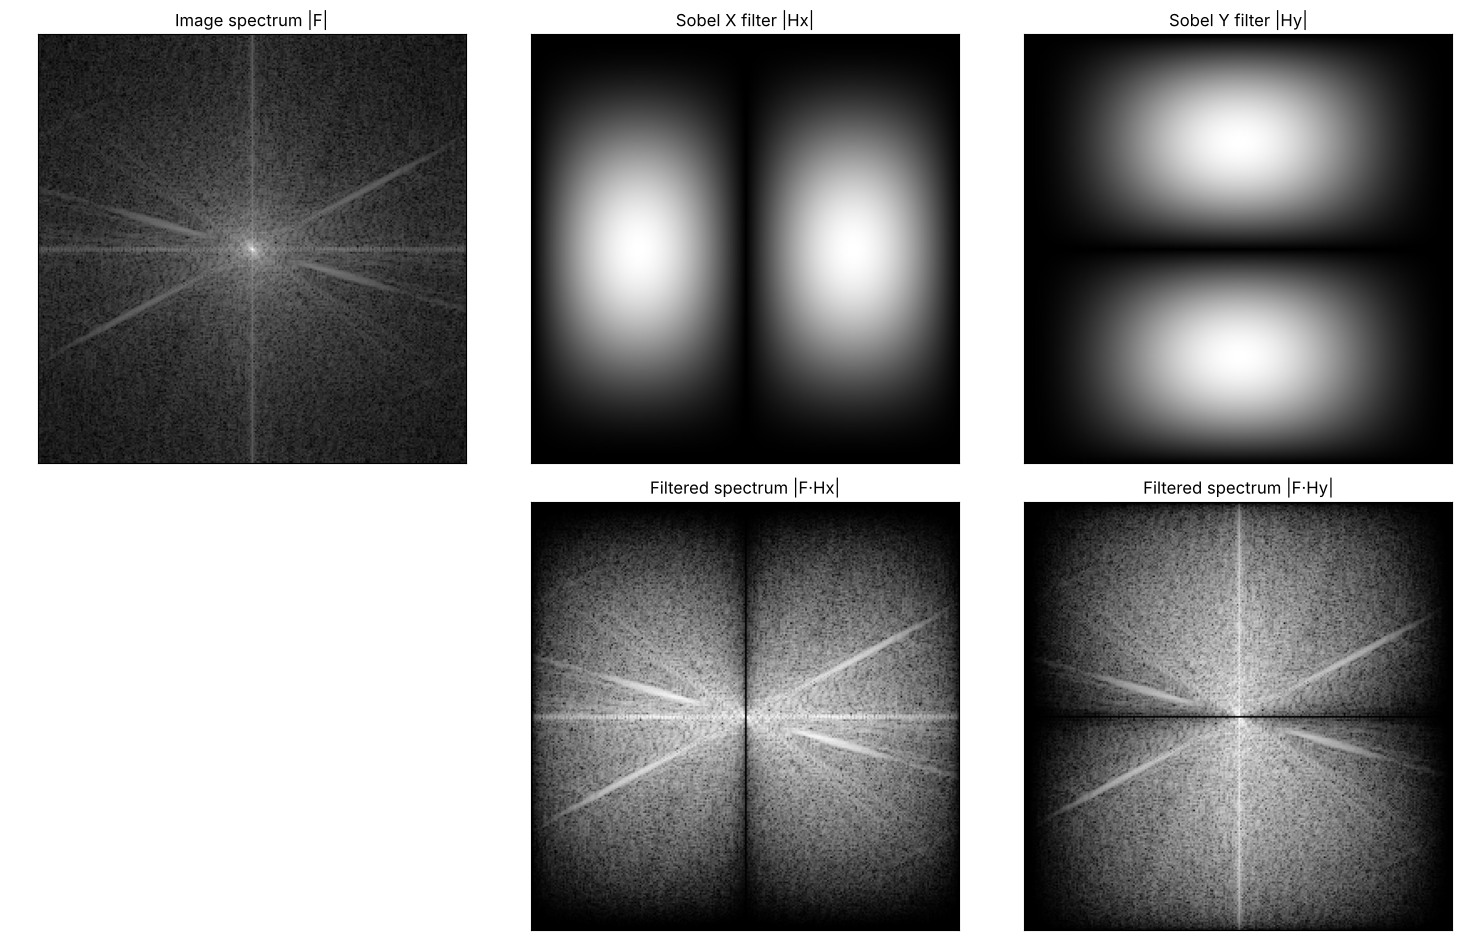

In [6]:
# Frequency-domain view: the Sobel filters' magnitude responses and the filtered spectra (centred)
fig, ax = plt.subplots(2, 3, figsize=(15, 9.5))
ax[0, 0].imshow(np.log(1 + np.abs(fftshift(F_img))), cmap='gray'); ax[0, 0].set_title('Image spectrum |F|')
ax[0, 1].imshow(fftshift(np.abs(H_x)), cmap='gray');               ax[0, 1].set_title('Sobel X filter |Hx|')
ax[0, 2].imshow(fftshift(np.abs(H_y)), cmap='gray');               ax[0, 2].set_title('Sobel Y filter |Hy|')
ax[1, 0].axis('off')
ax[1, 1].imshow(np.log(1 + np.abs(fftshift(F_gx))), cmap='gray'); ax[1, 1].set_title('Filtered spectrum |F·Hx|')
ax[1, 2].imshow(np.log(1 + np.abs(fftshift(F_gy))), cmap='gray'); ax[1, 2].set_title('Filtered spectrum |F·Hy|')
for a in ax.ravel(): a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.savefig('images/task1_sobel_spectra.png', dpi=100, bbox_inches='tight'); plt.show()

In [7]:
from scipy.ndimage import convolve

gx_spatial = convolve(image, sobel_x, mode='wrap')
gy_spatial = convolve(image, sobel_y, mode='wrap')

print('Max |difference| Sobel X :', np.abs(gx - gx_spatial).max())
print('Max |difference| Sobel Y :', np.abs(gy - gy_spatial).max())
print('Frequency-domain result matches spatial convolution:',
      np.allclose(gx, gx_spatial) and np.allclose(gy, gy_spatial))

Max |difference| Sobel X : 1.4883927423881005e-15
Max |difference| Sobel Y : 2.8380076066980564e-15
Frequency-domain result matches spatial convolution: True
